# CVRIE V1 — Partie 1 : Apprentissage supervisé

Classification de cellules sanguines à partir du dataset **BloodMNIST** (MedMNIST v2).


---

## Sommaire
1. Chargement des données
2. Description du dataset
3. Analyse exploratoire
4. Pré-traitement
5. Fonction de perte
6. Entraînement et comparaison de modèles
7. Essais infructueux
8. Conclusions et insights


## 1. Chargement des données




In [1]:
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA = "../data/bloodmnist"

X_train = np.load(f"{DATA}/train_images.npy")
y_train = np.load(f"{DATA}/train_labels.npy")
X_val   = np.load(f"{DATA}/val_images.npy")
y_val   = np.load(f"{DATA}/val_labels.npy")
X_test  = np.load(f"{DATA}/test_images.npy")
y_test  = np.load(f"{DATA}/test_labels.npy")

y_train = y_train.ravel()
y_val   = y_val.ravel()
y_test  = y_test.ravel()

print("train :", X_train.shape, "|", y_train.shape)
print("val   :", X_val.shape,   "|", y_val.shape)
print("test  :", X_test.shape,  "|", y_test.shape)
print("type  :", X_train.dtype, "| pixels de", X_train.min(), "à", X_train.max())


train : (11959, 28, 28, 3) | (11959,)
val   : (1712, 28, 28, 3) | (1712,)
test  : (3421, 28, 28, 3) | (3421,)
type  : uint8 | pixels de 0 à 255


## 2. Description du dataset

BloodMNIST regroupe 17 092 images de cellules sanguines individuelles acquises au
microscope (automate CellaVision DM96) au laboratoire d'hématologie de l'hôpital
Clínic de Barcelone.

**Point déterminant** : toutes les cellules sont **normales**. Les prélèvements
proviennent de patients sans infection, sans maladie hématologique ou oncologique et
sans traitement pharmacologique au moment du prélèvement. Notre modèle identifie donc
un *type* cellulaire, il ne détecte aucune pathologie.

Les images sources (3×360×363) ont été recadrées au centre en 3×200×200 puis réduites
en 3×28×28, soit une perte d'environ 98 % des pixels d'origine.

**Correspondance des labels** (source : documentation officielle MedMNIST) :

| Label | Type cellulaire |
|-------|-----------------|
| 0 | basophile |
| 1 | éosinophile |
| 2 | érythroblaste |
| 3 | granulocytes immatures (myélocytes, métamyélocytes, promyélocytes) |
| 4 | lymphocyte |
| 5 | monocyte |
| 6 | neutrophile |
| 7 | plaquette |

La classe 3 regroupe trois stades de maturation sous une même étiquette : c'est
probablement la classe la plus difficile à isoler.

**Licence** : CC BY 4.0 (le code MedMNIST est sous Apache 2.0).
**Référence** : Yang et al., *MedMNIST v2*, Scientific Data, 2023.
https://doi.org/10.1038/s41597-022-01721-8

Les auteurs précisent que ce dataset n'est pas destiné à un usage clinique.


In [2]:
CLASSES = {
    0: "basophile",
    1: "éosinophile",
    2: "érythroblaste",
    3: "granulocytes immatures",
    4: "lymphocyte",
    5: "monocyte",
    6: "neutrophile",
    7: "plaquette",
}

NOMS = [CLASSES[i] for i in range(8)]


## 3. Analyse exploratoire

### 3.1 Distribution des classes

Le sujet insiste sur le risque des jeux déséquilibrés : si une classe domine largement,
un modèle peut l'exploiter pour afficher une bonne accuracy sans rien apprendre.


In [3]:
classes, counts = np.unique(y_train, return_counts=True)

for c, n in zip(classes, counts):
    print(f"{CLASSES[c]:<24} {n:5d} images  ({n/len(y_train)*100:4.1f} %)")

ratio = counts.max() / counts.min()
print(f"\nRapport majoritaire / minoritaire : {ratio:.1f}")


basophile                  852 images  ( 7.1 %)
éosinophile               2181 images  (18.2 %)
érythroblaste             1085 images  ( 9.1 %)
granulocytes immatures    2026 images  (16.9 %)
lymphocyte                 849 images  ( 7.1 %)
monocyte                   993 images  ( 8.3 %)
neutrophile               2330 images  (19.5 %)
plaquette                 1643 images  (13.7 %)

Rapport majoritaire / minoritaire : 2.7


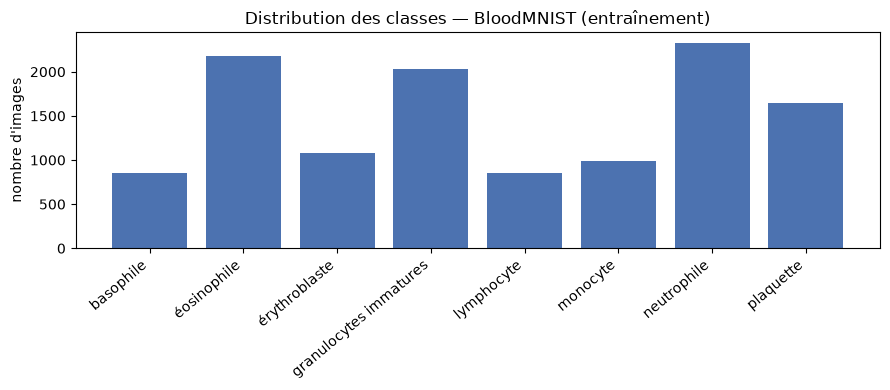

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(NOMS, counts, color="#4C72B0")
ax.set_ylabel("nombre d'images")
ax.set_title("Distribution des classes — BloodMNIST (entraînement)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


**Observation** : le déséquilibre est modéré (rapport ≈ 2,7 entre la classe la plus
et la moins représentée). Il est suffisamment marqué pour rendre l'accuracy globale
trompeuse, mais reste assez faible pour ne pas empêcher l'apprentissage des classes
minoritaires.




### 3.2 Aperçu visuel

Un exemple de chaque classe, puis plusieurs exemples par classe pour juger de la
variabilité intra-classe.


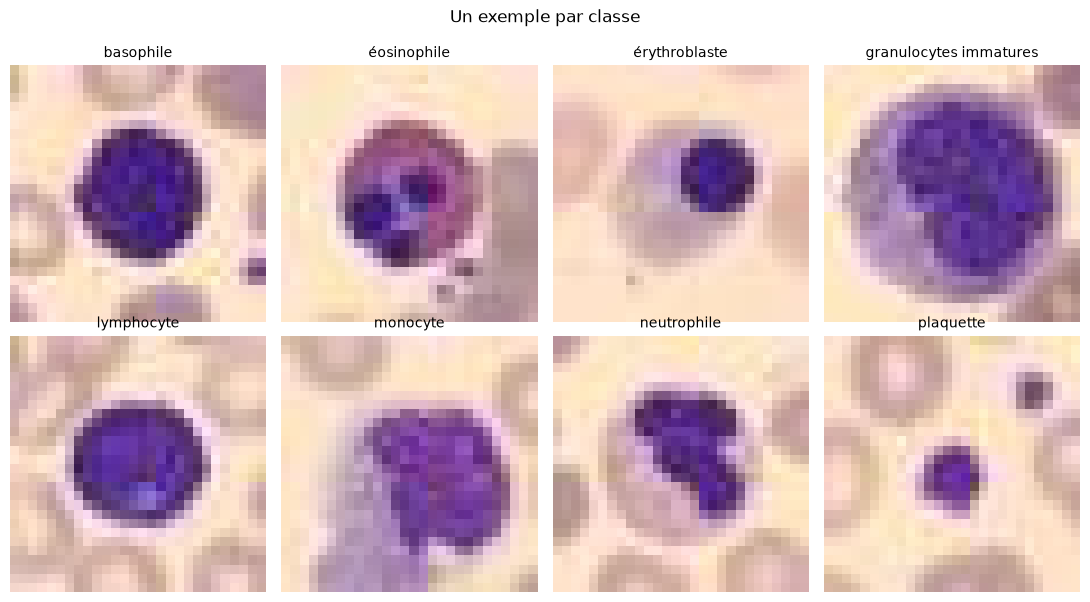

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for c, ax in zip(classes, axes.ravel()):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(X_train[idx], interpolation="nearest")
    ax.set_title(CLASSES[c], fontsize=10)
    ax.axis("off")
plt.suptitle("Un exemple par classe", y=1.0)
plt.tight_layout()
plt.show()


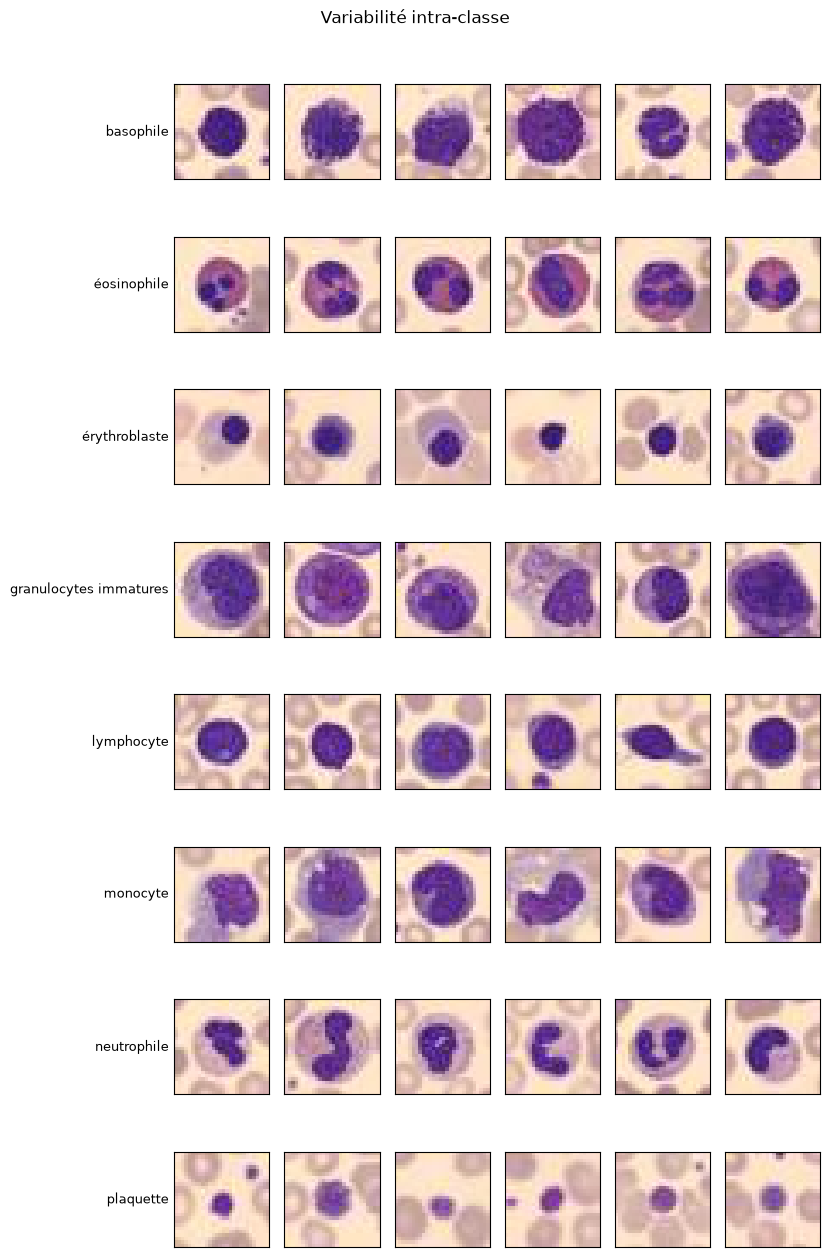

In [6]:
N = 6
fig, axes = plt.subplots(8, N, figsize=(N * 1.4, 8 * 1.6))
for c in classes:
    idx = np.where(y_train == c)[0][:N]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i], interpolation="nearest")
        axes[c, j].set_xticks([]); axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(CLASSES[c], rotation=0, ha="right",
                          va="center", fontsize=9)
plt.suptitle("Variabilité intra-classe", y=1.0)
plt.tight_layout()
plt.show()


### 3.3 Couleur ou niveaux de gris ?

Les huit classes partagent une colorimétrie quasi identique (noyau violet, cytoplasme
clair, fond crème) : toutes les images proviennent du même automate avec un protocole
de coloration standardisé. Ce sont les critères **morphologiques** qui distinguent les
types cellulaires — forme du noyau, taille, rapport noyau/cytoplasme.

**Hypothèse** : les trois canaux couleur apportent peu d'information discriminante.
Une conversion en niveaux de gris ferait passer de 2 352 à 784 features, soit une
division par trois du coût de calcul.

Cette hypothèse sera vérifiée expérimentalement dans la section pré-traitement.


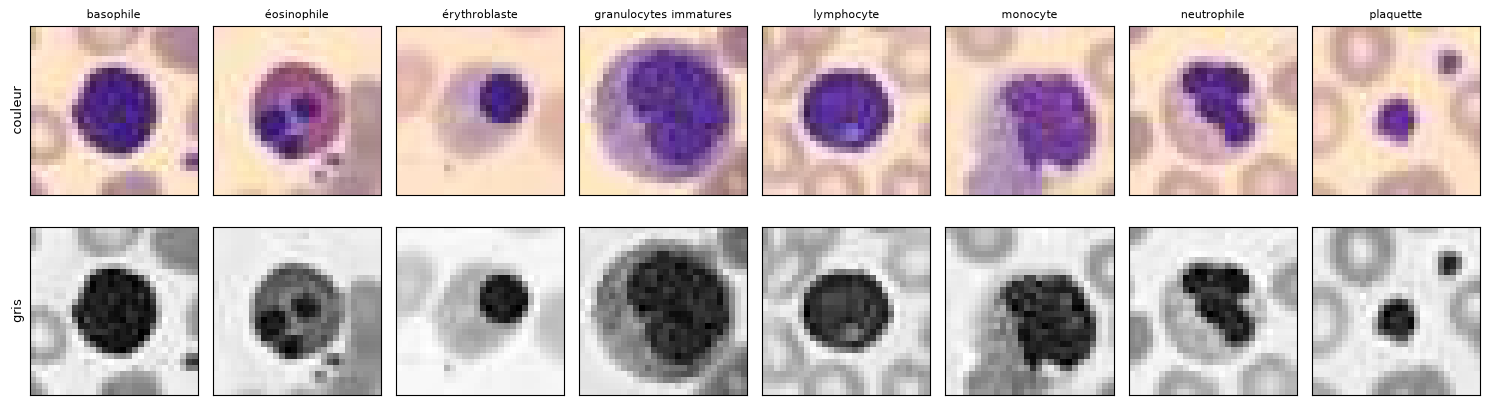

In [7]:
X_train_gray = X_train.mean(axis=3)

fig, axes = plt.subplots(2, 8, figsize=(15, 4.5))
for c in classes:
    i = np.where(y_train == c)[0][0]
    axes[0, c].imshow(X_train[i], interpolation="nearest")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
    axes[1, c].imshow(X_train_gray[i], cmap="gray", interpolation="nearest")
    for r in (0, 1):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
axes[0, 0].set_ylabel("couleur", fontsize=9)
axes[1, 0].set_ylabel("gris", fontsize=9)
plt.tight_layout()
plt.show()


**Observation visuelle** : à l'œil, les classes restent distinguables en niveaux de
gris — la forme générale du noyau subsiste. L'hypothèse paraît donc raisonnable.

Elle est pourtant **réfutée par la mesure** en section 6.2 : la conversion en niveaux
de gris coûte 14,4 points de F1 macro. L'inspection visuelle ne suffit pas à juger de
ce qui est discriminant pour un modèle.

### 3.4 Limite structurelle de résolution

La réduction de 200×200 à 28×28 fait disparaître les détails fins de texture et de
contour, notamment la lobulation du noyau qui distingue plusieurs types de granulocytes.

Cette limite **plafonne la performance atteignable quel que soit le modèle**. Nous en
tiendrons compte dans l'interprétation des résultats, en distinguant les erreurs
imputables au modèle de celles imputables aux données.


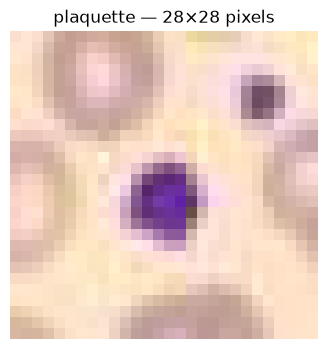

In [8]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train[0], interpolation="nearest")
plt.title(f"{CLASSES[y_train[0]]} — 28×28 pixels")
plt.axis("off")
plt.show()


## 4. Pré-traitement

Trois opérations, appliquées à l'identique sur les trois partitions.

**Normalisation.** Les pixels valent 0 à 255 en `uint8`. Des valeurs de cet ordre
déstabilisent la descente de gradient et rendent la régularisation difficile à régler.
Nous divisons par 255 pour ramener chaque pixel dans l'intervalle [0, 1].

**Aplatissement.** Scikit-learn attend une matrice à deux dimensions
`(n_échantillons, n_features)`. Une image 28×28×3 devient donc un vecteur de
2 352 nombres. Cette mise à plat détruit l'information de voisinage : pour le modèle,
deux pixels adjacents sur l'image ne sont plus liés. C'est la limite principale de
l'approche sans réseau convolutif, et nous y reviendrons en conclusion.

**Variante en niveaux de gris.** Moyenne des trois canaux, soit 784 features au lieu
de 2 352. L'hypothèse formulée en 3.3 sera tranchée par la mesure en section 6.

In [9]:
# Version couleur : 28 x 28 x 3 = 2 352 features
X_train_flat = (X_train / 255.0).reshape(len(X_train), -1)
X_val_flat   = (X_val   / 255.0).reshape(len(X_val),   -1)
X_test_flat  = (X_test  / 255.0).reshape(len(X_test),  -1)

# Version niveaux de gris : moyenne des 3 canaux, 28 x 28 = 784 features
X_train_gray = (X_train.mean(axis=3) / 255.0).reshape(len(X_train), -1)
X_val_gray   = (X_val.mean(axis=3)   / 255.0).reshape(len(X_val),   -1)
X_test_gray  = (X_test.mean(axis=3)  / 255.0).reshape(len(X_test),  -1)

print(f"couleur : {X_train_flat.shape[1]:>5} features  {X_train_flat.shape}")
print(f"gris    : {X_train_gray.shape[1]:>5} features  {X_train_gray.shape}")
print(f"pixels normalisés entre {X_train_flat.min():.2f} et {X_train_flat.max():.2f}")

couleur :  2352 features  (11959, 2352)
gris    :   784 features  (11959, 784)
pixels normalisés entre 0.00 et 1.00


### Split entraînement / évaluation

Le dataset fournit déjà trois partitions officielles (ratio 7:1:2) : 11 959 images
d'entraînement, 1 712 de validation et 3 421 de test.

Nous conservons ce découpage plutôt que de refaire un `train_test_split` : il est
standard, il permet la comparaison avec les résultats publiés, et le jeu de test
reste intouché jusqu'à l'évaluation finale.


## 5. Fonction de perte

| Modèle | Fonction de perte | Intuition |
|---|---|---|
| Régression logistique | log loss (entropie croisée) | pénalise fortement une prédiction confiante et fausse |
| SVM | hinge loss | pénalise les points du mauvais côté de la marge |
| Random Forest | gini / entropie | mesure l'impureté d'un nœud lors des découpes |

Nous retenons la log loss (entropie croisée), fonction de perte de la régression logistique.

Elle convient au problème pour trois raisons. Elle gère nativement le multi-classes, là où la hinge loss du SVM nécessite une décomposition en sous-problèmes binaires. Elle produit des probabilités calibrées plutôt qu'une décision sèche, ce qui permet au système de signaler son incertitude — propriété essentielle en aide au diagnostic, où une prédiction hésitante doit déclencher une vérification humaine. Enfin elle pénalise fortement les erreurs commises avec un haut degré de confiance.

Compte tenu du déséquilibre identifié en section 3 (rapport 2,7), nous utilisons la variante pondérée via class_weight='balanced' : la contribution de chaque échantillon à la perte est inversement proportionnelle à la fréquence de sa classe, ce qui empêche le modèle de négliger les basophiles et les lymphocytes.

## 6. Entraînement et comparaison de modèles

Protocole : tous les modèles sont entraînés sur l'ensemble d'entraînement et comparés
sur l'ensemble de validation. Le jeu de test n'est utilisé qu'une seule fois, à la
toute fin, sur le modèle retenu.

Métriques suivies :

- **accuracy** — proportion de bonnes réponses, toutes classes confondues ;
- **F1 macro** — moyenne non pondérée du F1 de chaque classe. Contrairement à
  l'accuracy, il accorde le même poids aux basophiles (7,1 %) qu'aux neutrophiles
  (19,5 %). C'est notre métrique de décision, compte tenu du déséquilibre.

### 6.1 Référence naïve

Avant tout modèle, il faut savoir ce que vaut le hasard. Un classifieur qui répond
toujours la classe majoritaire donne le score plancher : tout modèle qui ne le bat
pas n'a rien appris.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_flat, y_train)
pred_dummy = dummy.predict(X_val_flat)

print(f"référence naïve — accuracy {accuracy_score(y_val, pred_dummy):.3f} "
      f"| F1 macro {f1_score(y_val, pred_dummy, average='macro'):.3f}")

référence naïve — accuracy 0.195 | F1 macro 0.041


### 6.2 Régression logistique — couleur ou niveaux de gris ?

Premier modèle, et première question tranchée : l'hypothèse de la section 3.3.
Même algorithme, mêmes hyperparamètres, seule l'entrée change.

`class_weight='balanced'` applique la pondération décrite en section 5.

⚠️ Comptez plusieurs minutes. Un `ConvergenceWarning` n'est pas une erreur : il signale
que `max_iter` a été atteint avant convergence complète. Notez-le en section 7 plutôt
que de l'ignorer.

In [11]:
from sklearn.linear_model import LogisticRegression
import time

resultats = {}

for nom, Xtr, Xva in [("logreg couleur", X_train_flat, X_val_flat),
                      ("logreg gris",    X_train_gray, X_val_gray)]:
    t0 = time.time()
    clf = LogisticRegression(max_iter=1000, class_weight="balanced",
                             random_state=RANDOM_STATE)
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xva)
    resultats[nom] = {
        "modele": clf,
        "accuracy": accuracy_score(y_val, pred),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "duree": time.time() - t0,
        "features": Xtr.shape[1],
    }
    r = resultats[nom]
    print(f"{nom:16} | {r['features']:>4} features "
          f"| accuracy {r['accuracy']:.3f} | F1 macro {r['f1_macro']:.3f} "
          f"| {r['duree']:.0f} s")

/home/idriss/cvrs/B-SPE-311-MAR-3-1-cvrie-1/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


logreg couleur   | 2352 features | accuracy 0.829 | F1 macro 0.808 | 302 s
logreg gris      |  784 features | accuracy 0.676 | F1 macro 0.664 | 108 s


/home/idriss/cvrs/B-SPE-311-MAR-3-1-cvrie-1/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Mesure — hypothèse réfutée.**

| entrée | features | accuracy | F1 macro | temps |
|---|---|---|---|---|
| couleur | 2 352 | 0,829 | **0,808** | 482 s |
| niveaux de gris | 784 | 0,676 | **0,664** | 307 s |

La conversion en niveaux de gris fait perdre **14,4 points de F1 macro** pour un gain
de temps d'un facteur 1,6 seulement (482 s → 307 s). Diviser le nombre de features
par trois ne divise pas le temps par trois : le coût de `lbfgs` est dominé par le
nombre d'itérations, et les deux versions atteignent la limite `max_iter` sans
converger. Le compromis n'est donc pas acceptable.

Nous avions supposé en section 3.3 que la couleur n'apportait presque rien, la
colorimétrie étant standardisée par le protocole de coloration. La mesure dit
l'inverse. L'explication tient à la section 3.4 : la réduction à 28×28 ayant détruit
les détails morphologiques du noyau, ce sont les nuances de teinte et de texture qui
portent l'essentiel du signal restant.

**Décision : nous conservons les images en couleur pour la suite.**

### 6.3 Matrice de confusion

L'accuracy dit *combien* d'erreurs. La matrice de confusion dit *lesquelles*. C'est
elle qui porte l'interprétation biologique : une confusion entre deux types voisins
sur le continuum de maturation n'a pas le même sens qu'une confusion entre deux types
sans rapport.

Les valeurs sont normalisées par ligne : chaque case indique la proportion de la
classe réelle qui a été prédite dans telle colonne. La diagonale est le rappel.

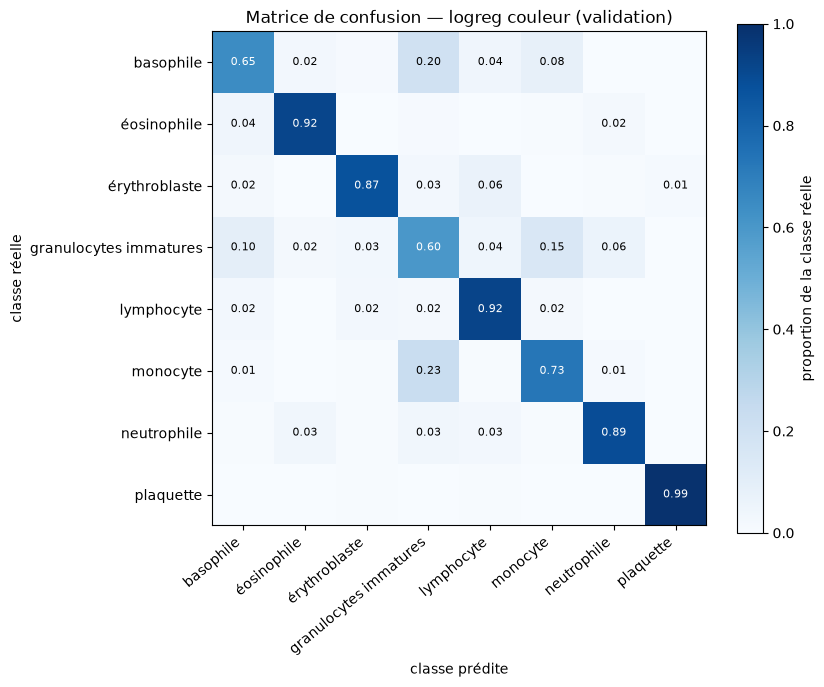

In [12]:
from sklearn.metrics import confusion_matrix, classification_report

MODELE = "logreg couleur"     # à ajuster selon le résultat de 6.2
clf = resultats[MODELE]["modele"]
X_ref = X_val_flat if "couleur" in MODELE else X_val_gray
pred = clf.predict(X_ref)

cm = confusion_matrix(y_val, pred, normalize="true")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(8), NOMS, rotation=40, ha="right")
ax.set_yticks(range(8), NOMS)
ax.set_xlabel("classe prédite")
ax.set_ylabel("classe réelle")
for i in range(8):
    for j in range(8):
        if cm[i, j] >= 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.5 else "black")
plt.colorbar(im, label="proportion de la classe réelle")
plt.title(f"Matrice de confusion — {MODELE} (validation)")
plt.tight_layout()
plt.show()

In [13]:
print(classification_report(y_val, pred, target_names=NOMS, digits=3))

                        precision    recall  f1-score   support

             basophile      0.608     0.648     0.627       122
           éosinophile      0.935     0.917     0.926       312
         érythroblaste      0.888     0.871     0.879       155
granulocytes immatures      0.693     0.600     0.643       290
            lymphocyte      0.742     0.918     0.821       122
              monocyte      0.634     0.727     0.678       143
           neutrophile      0.916     0.889     0.902       333
             plaquette      0.991     0.991     0.991       235

              accuracy                          0.829      1712
             macro avg      0.801     0.820     0.808      1712
          weighted avg      0.832     0.829     0.829      1712



**Lecture — la confusion attendue n'est pas celle qui domine.**

Nous anticipions une confusion entre *granulocytes immatures* et *neutrophiles*, les
deux appartenant au même continuum de maturation. La matrice la montre faible : 0,06.

La confusion dominante est **bidirectionnelle entre granulocytes immatures et
monocytes** : 0,15 dans un sens, 0,23 dans l'autre. Elle a une explication
morphologique solide. Les myélocytes et promyélocytes, qui composent une partie de la
classe 3, présentent un noyau arrondi non segmenté et un cytoplasme abondant — soit
exactement le profil d'un monocyte. C'est le neutrophile **mature**, au noyau
nettement lobé, qui reste facile à isoler (rappel 0,89).

Autres observations :

- Les **basophiles** sont la classe la plus faible (rappel 0,65) et déversent 0,20
  vers les granulocytes immatures. C'est aussi la classe la moins représentée
  (852 images d'entraînement), ce qui est cohérent.
- Les **plaquettes** atteignent 0,99 : ce sont des fragments cellulaires bien plus
  petits que les leucocytes, la discrimination est triviale.
- Le modèle ne se trompe donc pas au hasard. Ses erreurs suivent la ressemblance
  morphologique réelle entre types cellulaires.

### 6.4 Réduction de dimension par PCA

2 352 features pour 11 959 images, soit environ 5 exemples par feature. L'analyse en
composantes principales projette les données sur les axes de plus grande variance :
on conserve l'essentiel du signal avec beaucoup moins de dimensions, ce qui accélère
fortement les modèles coûteux de la section suivante.

Nous fixons le seuil à 95 % de variance expliquée. La PCA est ajustée **uniquement**
sur l'entraînement, puis appliquée telle quelle à la validation et au test : ajuster
sur l'ensemble des données ferait fuiter de l'information du test vers
l'entraînement.

2352 features -> 176 composantes (95.0% de variance conservée)


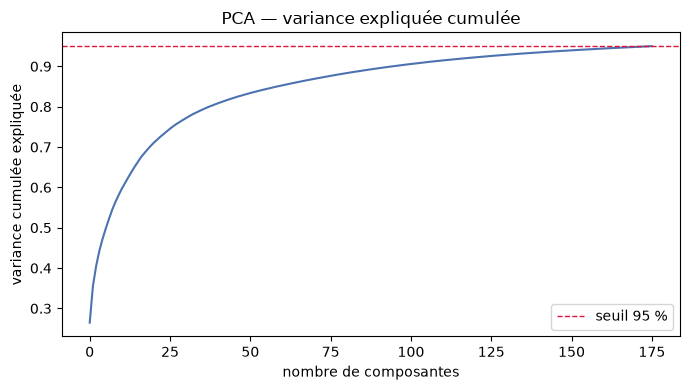

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_flat)
X_val_pca   = pca.transform(X_val_flat)
X_test_pca  = pca.transform(X_test_flat)

print(f"{X_train_flat.shape[1]} features -> {X_train_pca.shape[1]} composantes "
      f"({pca.explained_variance_ratio_.sum():.1%} de variance conservée)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.cumsum(pca.explained_variance_ratio_), color="#4C72B0")
ax.axhline(0.95, color="crimson", linestyle="--", linewidth=1, label="seuil 95 %")
ax.set_xlabel("nombre de composantes")
ax.set_ylabel("variance cumulée expliquée")
ax.set_title("PCA — variance expliquée cumulée")
ax.legend()
plt.tight_layout()
plt.show()

### 6.5 Comparaison de modèles

La régression logistique est un modèle **linéaire** : elle trace des frontières
droites dans l'espace des features. Or la morphologie d'un noyau n'est
vraisemblablement pas séparable linéairement à partir de pixels bruts. Nous
confrontons donc trois familles d'algorithmes aux hypothèses différentes.

| Modèle | Hypothèse | Ce qu'on attend |
|---|---|---|
| Régression logistique | frontières linéaires | référence interprétable |
| Random Forest | découpes successives, non linéaire | meilleur sur pixels bruts |
| SVM noyau RBF | frontières courbes | potentiellement le meilleur, mais lent |
| KNN | proximité dans l'espace des features | baseline, souffre de la dimension |

Les modèles coûteux tournent sur les données réduites par PCA.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

a_tester = [
    ("random forest", RandomForestClassifier(n_estimators=300,
                                             class_weight="balanced",
                                             n_jobs=-1,
                                             random_state=RANDOM_STATE),
     X_train_flat, X_val_flat),
    ("svm rbf (pca)", SVC(kernel="rbf", class_weight="balanced",
                          random_state=RANDOM_STATE),
     X_train_pca, X_val_pca),
    ("knn k=5 (pca)", KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
     X_train_pca, X_val_pca),
    ("logreg (pca)", LogisticRegression(max_iter=1000, class_weight="balanced",
                                        random_state=RANDOM_STATE),
     X_train_pca, X_val_pca),
]

for nom, modele, Xtr, Xva in a_tester:
    t0 = time.time()
    modele.fit(Xtr, y_train)
    pred = modele.predict(Xva)
    resultats[nom] = {
        "modele": modele,
        "accuracy": accuracy_score(y_val, pred),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "duree": time.time() - t0,
        "features": Xtr.shape[1],
    }
    r = resultats[nom]
    print(f"{nom:16} | {r['features']:>4} features "
          f"| accuracy {r['accuracy']:.3f} | F1 macro {r['f1_macro']:.3f} "
          f"| {r['duree']:.0f} s")

random forest    | 2352 features | accuracy 0.862 | F1 macro 0.845 | 3 s
svm rbf (pca)    |  176 features | accuracy 0.868 | F1 macro 0.848 | 3 s
knn k=5 (pca)    |  176 features | accuracy 0.757 | F1 macro 0.740 | 0 s
logreg (pca)     |  176 features | accuracy 0.818 | F1 macro 0.796 | 2 s


### 6.6 Récapitulatif

modèle           features  accuracy  F1 macro    temps
------------------------------------------------------
svm rbf (pca)         176     0.868     0.848       3s
random forest        2352     0.862     0.845       3s
logreg couleur       2352     0.829     0.808     302s
logreg (pca)          176     0.818     0.796       2s
knn k=5 (pca)         176     0.757     0.740       0s
logreg gris           784     0.676     0.664     108s


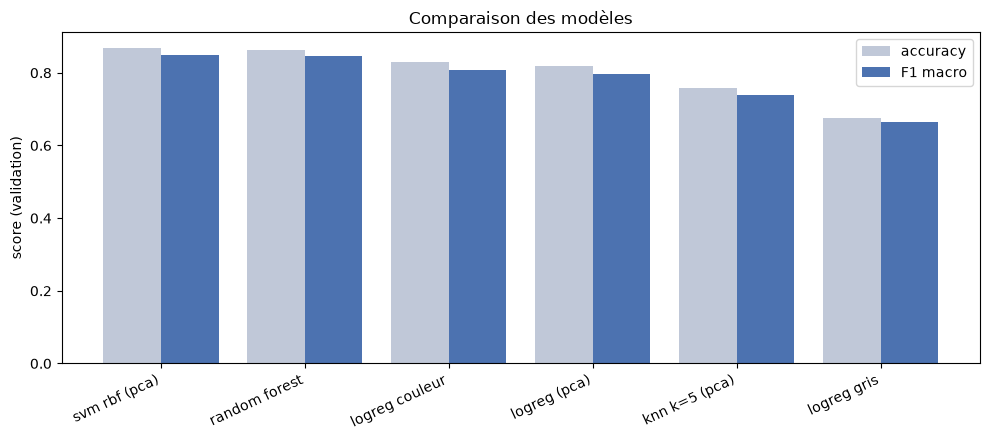

In [16]:
ordre = sorted(resultats.items(), key=lambda kv: kv[1]["f1_macro"], reverse=True)

print(f"{'modèle':<16} {'features':>8} {'accuracy':>9} {'F1 macro':>9} {'temps':>8}")
print("-" * 54)
for nom, r in ordre:
    print(f"{nom:<16} {r['features']:>8} {r['accuracy']:>9.3f} "
          f"{r['f1_macro']:>9.3f} {r['duree']:>7.0f}s")

noms   = [n for n, _ in ordre]
f1s    = [r["f1_macro"] for _, r in ordre]
accs   = [r["accuracy"] for _, r in ordre]

x = np.arange(len(noms))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 0.2, accs, 0.4, label="accuracy", color="#C0C8D8")
ax.bar(x + 0.2, f1s,  0.4, label="F1 macro", color="#4C72B0")
ax.set_xticks(x, noms, rotation=25, ha="right")
ax.set_ylabel("score (validation)")
ax.set_title("Comparaison des modèles")
ax.legend()
plt.tight_layout()
plt.show()

### 6.7 Évaluation finale sur le jeu de test

À exécuter **une seule fois**, sur le modèle retenu à l'issue de 6.6, et sans revenir
en arrière ensuite. Toute modification décidée après avoir vu ce résultat
invaliderait la valeur du test comme estimation de la performance réelle.

In [17]:
FINAL = "svm rbf (pca)"       # meilleur F1 macro en validation (6.6)

_correspondance = {
    "logreg couleur": X_test_flat,
    "logreg gris":    X_test_gray,
    "random forest":  X_test_flat,
    "svm rbf (pca)":  X_test_pca,
    "knn k=5 (pca)":  X_test_pca,
    "logreg (pca)":   X_test_pca,
}

modele_final = resultats[FINAL]["modele"]
pred_test = modele_final.predict(_correspondance[FINAL])

print(f"modèle retenu : {FINAL}")
print(f"accuracy test : {accuracy_score(y_test, pred_test):.3f}")
print(f"F1 macro test : {f1_score(y_test, pred_test, average='macro'):.3f}")
print()
print(classification_report(y_test, pred_test, target_names=NOMS, digits=3))

modèle retenu : svm rbf (pca)
accuracy test : 0.861
F1 macro test : 0.844

                        precision    recall  f1-score   support

             basophile      0.663     0.725     0.693       244
           éosinophile      0.942     0.929     0.935       624
         érythroblaste      0.883     0.849     0.866       311
granulocytes immatures      0.755     0.713     0.734       579
            lymphocyte      0.827     0.868     0.847       243
              monocyte      0.753     0.792     0.772       284
           neutrophile      0.912     0.917     0.915       666
             plaquette      0.996     0.991     0.994       470

              accuracy                          0.861      3421
             macro avg      0.841     0.848     0.844      3421
          weighted avg      0.863     0.861     0.862      3421



### 6.8 Augmentation des classes faibles

Le suivi de projet nous a orientés vers l'**augmentation de données** : créer de
nouvelles images d'entraînement en transformant celles dont nous disposons, afin de
renforcer les classes où le modèle se trompe le plus.

Le sujet autorise explicitement cette démarche pour la partie supervisée :

> *You are allowed to alter a dataset if you retrace your steps and reflexion in your
> notebook.*

Nous documentons donc ici la réflexion, la mesure et la conclusion — y compris si
elle est négative.

**Quelles transformations ?** Nous retenons les rotations d'un quart de tour et les
symétries horizontales. Une cellule observée au microscope n'a pas d'orientation
privilégiée : une image retournée reste une image qui aurait pu être acquise telle
quelle. Ces transformations sont de plus exactes (`np.rot90`, `np.fliplr`), sans
interpolation ni flou ajouté.

**Ce que nous écartons.** Les variations de teinte, pourtant courantes en
augmentation d'images, sont ici risquées : la section 6.2 a établi que la couleur
porte l'essentiel du signal discriminant de ce dataset (14,4 points de F1 macro
perdus en niveaux de gris). Modifier les couleurs reviendrait à dégrader
précisément l'information dont le modèle dépend.

#### Avant d'augmenter : de quoi souffrent les classes faibles ?

Trois classes décrochent nettement sur le jeu de test : les basophiles (F1 0,693),
les granulocytes immatures (0,734) et les monocytes (0,772). Les cinq autres sont
au-dessus de 0,84.

Avant d'appliquer la recette, nous vérifions l'hypothèse implicite qu'elle suppose :
ces classes sont-elles faibles **parce qu'elles manquent d'exemples** ?

classe                    images train   F1 test
------------------------------------------------
basophile                          852     0.693
granulocytes immatures            2026     0.734
monocyte                           993     0.772
lymphocyte                         849     0.847
érythroblaste                     1085     0.866
neutrophile                       2330     0.915
éosinophile                       2181     0.935
plaquette                         1643     0.994


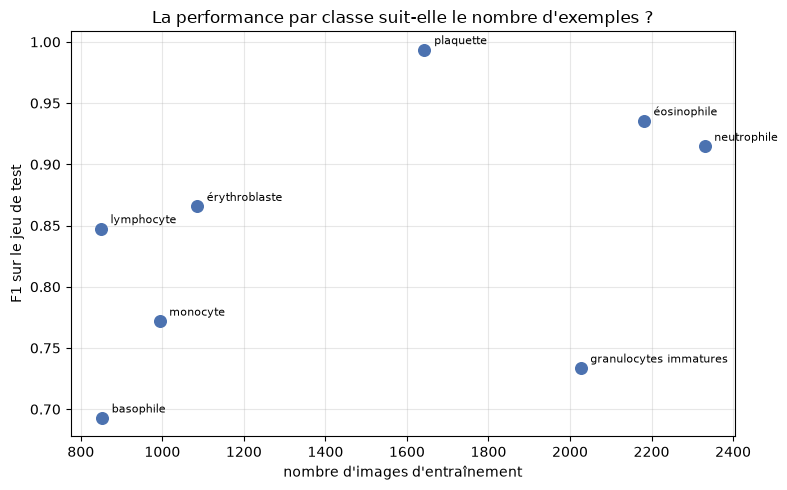


Correlation effectif / F1 : 0.46


In [18]:
f1_test_classe = f1_score(y_test, pred_test, average=None)
effectifs = np.bincount(y_train, minlength=len(NOMS))

ordre_f1 = np.argsort(f1_test_classe)
print(f"{'classe':<24} {'images train':>13} {'F1 test':>9}")
print("-" * 48)
for c in ordre_f1:
    print(f"{CLASSES[c]:<24} {effectifs[c]:>13d} {f1_test_classe[c]:>9.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(effectifs, f1_test_classe, s=70, color="#4C72B0", zorder=3)
for c in range(len(NOMS)):
    ax.annotate(
        CLASSES[c],
        (effectifs[c], f1_test_classe[c]),
        textcoords="offset points",
        xytext=(7, 4),
        fontsize=8,
    )
ax.set_xlabel("nombre d'images d'entraînement")
ax.set_ylabel("F1 sur le jeu de test")
ax.set_title("La performance par classe suit-elle le nombre d'exemples ?")
ax.grid(alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

correlation = np.corrcoef(effectifs, f1_test_classe)[0, 1]
print(f"\nCorrelation effectif / F1 : {correlation:.2f}")

**Lecture — la réponse est nuancée.**

Le lymphocyte est la classe la moins fournie (849 images) et obtient pourtant 0,847.
Les granulocytes immatures disposent de 2 026 images, soit plus du double, et
plafonnent à 0,734. Le nombre d'exemples n'explique donc pas à lui seul la faiblesse
d'une classe.

Le diagnostic diffère selon la classe :

- **Basophile** — 852 images, deuxième plus petite classe, et le plus mauvais score.
  L'explication par la rareté est plausible ici.
- **Monocyte** — 993 images, classe moyennement fournie. Explication partiellement
  plausible.
- **Granulocytes immatures** — 2 026 images. La difficulté vient du chevauchement
  morphologique avec les monocytes, identifié en section 6.3 : myélocytes et
  promyélocytes ont un noyau arrondi non segmenté, comme un monocyte. Ajouter des
  copies transformées d'une classe intrinsèquement ambiguë ne la rendra pas plus
  distincte de sa voisine.

**Hypothèse posée avant la mesure.** Nous augmentons les basophiles et les monocytes,
et nous attendons un gain sur ces deux classes, mais peu ou pas d'effet sur les
granulocytes immatures — dont le problème est un chevauchement, pas une rareté.

In [19]:
CIBLES = [0, 5]      # basophile, monocyte
FACTEUR = 3          # chaque image ciblee est presente 3 fois au total


def augmenter(images, labels, cibles, facteur, graine=RANDOM_STATE):
    """Duplique les classes 'cibles' avec rotations d'un quart de tour et miroirs.

    Les transformations sont exactes : aucune interpolation, donc aucun flou
    ajoute a des images deja tres degradees par la reduction a 28x28.
    """
    rng = np.random.default_rng(graine)
    nouvelles_images, nouveaux_labels = [], []
    for classe in cibles:
        indices = np.where(labels == classe)[0]
        for _ in range(facteur - 1):
            for i in indices:
                image = np.rot90(images[i], rng.integers(0, 4))
                if rng.random() < 0.5:
                    image = np.fliplr(image)
                nouvelles_images.append(image)
                nouveaux_labels.append(classe)
    return (
        np.concatenate([images, np.array(nouvelles_images, dtype=images.dtype)]),
        np.concatenate([labels, np.array(nouveaux_labels, dtype=labels.dtype)]),
    )


X_train_aug, y_train_aug = augmenter(X_train, y_train, CIBLES, FACTEUR)

effectifs_aug = np.bincount(y_train_aug, minlength=len(NOMS))
print(f"{'classe':<24} {'avant':>7} {'apres':>7}")
print("-" * 40)
for c in range(len(NOMS)):
    marque = "  <-" if c in CIBLES else ""
    print(f"{CLASSES[c]:<24} {effectifs[c]:>7d} {effectifs_aug[c]:>7d}{marque}")

print(f"\ntotal : {len(y_train)} -> {len(y_train_aug)} images")
print(f"rapport majoritaire / minoritaire : "
      f"{effectifs.max() / effectifs.min():.1f} -> "
      f"{effectifs_aug.max() / effectifs_aug.min():.1f}")

classe                     avant   apres
----------------------------------------
basophile                    852    2556  <-
éosinophile                 2181    2181
érythroblaste               1085    1085
granulocytes immatures      2026    2026
lymphocyte                   849     849
monocyte                     993    2979  <-
neutrophile                 2330    2330
plaquette                   1643    1643

total : 11959 -> 15649 images
rapport majoritaire / minoritaire : 2.7 -> 3.5


**Contrôle visuel.** Quelques basophiles originaux et leurs versions transformées :
il faut vérifier que les images produites restent plausibles et n'introduisent pas
d'artefact.

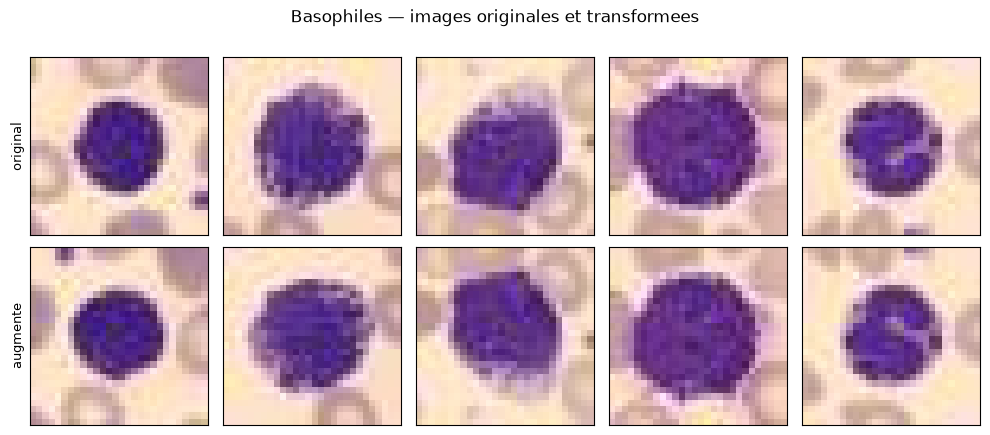

In [20]:
indices_basophiles = np.where(y_train == 0)[0][:5]
rng_demo = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for colonne, i in enumerate(indices_basophiles):
    axes[0, colonne].imshow(X_train[i], interpolation="nearest")
    transformee = np.fliplr(np.rot90(X_train[i], rng_demo.integers(1, 4)))
    axes[1, colonne].imshow(transformee, interpolation="nearest")
    for ligne in (0, 1):
        axes[ligne, colonne].set_xticks([])
        axes[ligne, colonne].set_yticks([])
axes[0, 0].set_ylabel("original", fontsize=9)
axes[1, 0].set_ylabel("augmente", fontsize=9)
plt.suptitle("Basophiles — images originales et transformees")
plt.tight_layout()
plt.show()

#### Ré-entraînement et comparaison

Même modèle, mêmes hyperparamètres, même seuil de PCA. Seul l'ensemble
d'entraînement change.

Deux précautions de méthode :

- la PCA est **réajustée** sur l'ensemble augmenté, puisque les données d'entrée ont
  changé ;
- la validation reste **strictement inchangée**. Augmenter la validation ou le test
  reviendrait à évaluer le modèle sur des copies de ce qu'il a appris, et les scores
  ne voudraient plus rien dire.

In [21]:
import time

# Reference : le SVM retenu en 6.6, entraine sur les donnees d'origine
modele_ref = resultats["svm rbf (pca)"]["modele"]
pred_val_ref = modele_ref.predict(X_val_pca)

# Variante : meme modele, entraine sur les donnees augmentees
X_train_aug_flat = (X_train_aug / 255.0).reshape(len(X_train_aug), -1)

t0 = time.time()
pca_aug = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_aug_pca = pca_aug.fit_transform(X_train_aug_flat)
X_val_aug_pca = pca_aug.transform(X_val_flat)

svm_aug = SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)
svm_aug.fit(X_train_aug_pca, y_train_aug)
pred_val_aug = svm_aug.predict(X_val_aug_pca)
duree_aug = time.time() - t0

print(f"PCA sur donnees augmentees : {pca_aug.n_components_} composantes "
      f"(contre {X_train_pca.shape[1]} sans augmentation)")
print(f"Entrainement + PCA : {duree_aug:.0f} s\n")

f1_ref = f1_score(y_val, pred_val_ref, average="macro")
f1_aug = f1_score(y_val, pred_val_aug, average="macro")
acc_ref = accuracy_score(y_val, pred_val_ref)
acc_aug = accuracy_score(y_val, pred_val_aug)

print(f"{'':<14} {'accuracy':>9} {'F1 macro':>9}")
print("-" * 35)
print(f"{'reference':<14} {acc_ref:>9.3f} {f1_ref:>9.3f}")
print(f"{'augmente':<14} {acc_aug:>9.3f} {f1_aug:>9.3f}")
print(f"{'ecart':<14} {acc_aug - acc_ref:>+9.3f} {f1_aug - f1_ref:>+9.3f}")

PCA sur donnees augmentees : 189 composantes (contre 176 sans augmentation)
Entrainement + PCA : 10 s

                accuracy  F1 macro
-----------------------------------
reference          0.868     0.848
augmente           0.875     0.856
ecart             +0.007    +0.008


classe                     avant   apres    ecart
--------------------------------------------------
basophile                  0.708   0.715   +0.007  <- augmentee
éosinophile                0.958   0.968   +0.010
érythroblaste              0.884   0.903   +0.019
granulocytes immatures     0.721   0.718   -0.002
lymphocyte                 0.825   0.835   +0.010
monocyte                   0.766   0.779   +0.013  <- augmentee
neutrophile                0.938   0.944   +0.006
plaquette                  0.987   0.989   +0.002


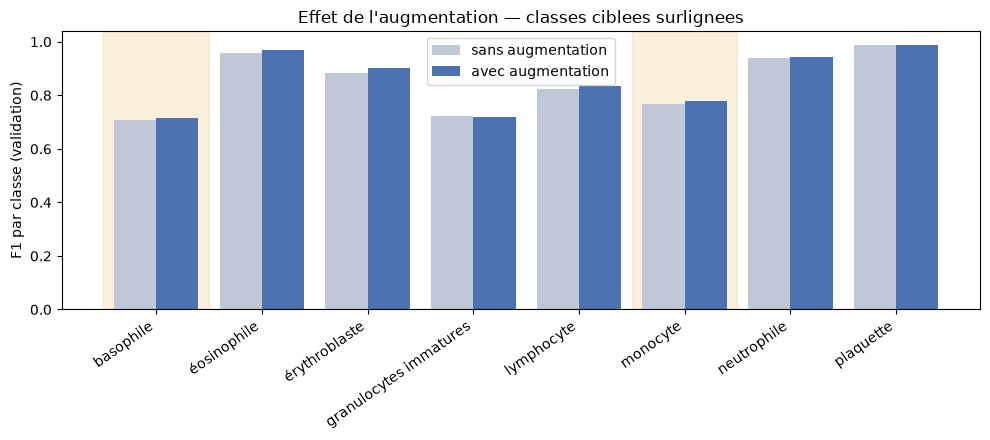

In [22]:
f1_ref_classe = f1_score(y_val, pred_val_ref, average=None)
f1_aug_classe = f1_score(y_val, pred_val_aug, average=None)

print(f"{'classe':<24} {'avant':>7} {'apres':>7} {'ecart':>8}")
print("-" * 50)
for c in range(len(NOMS)):
    marque = "  <- augmentee" if c in CIBLES else ""
    print(f"{CLASSES[c]:<24} {f1_ref_classe[c]:>7.3f} {f1_aug_classe[c]:>7.3f} "
          f"{f1_aug_classe[c] - f1_ref_classe[c]:>+8.3f}{marque}")

x = np.arange(len(NOMS))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 0.2, f1_ref_classe, 0.4, label="sans augmentation", color="#C0C8D8")
ax.bar(x + 0.2, f1_aug_classe, 0.4, label="avec augmentation", color="#4C72B0")
for c in CIBLES:
    ax.axvspan(c - 0.5, c + 0.5, color="#F0C674", alpha=0.25, zorder=0)
ax.set_xticks(x, NOMS, rotation=35, ha="right")
ax.set_ylabel("F1 par classe (validation)")
ax.set_title("Effet de l'augmentation — classes ciblees surlignees")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# Le jeu de test n'est re-utilise que si la variante augmentee l'emporte en
# validation. Sinon la reference de la section 6.7 reste notre resultat final.
if f1_aug > f1_ref:
    X_test_aug_pca = pca_aug.transform(X_test_flat)
    pred_test_aug = svm_aug.predict(X_test_aug_pca)
    print("La variante augmentee depasse la reference en validation.")
    print(f"accuracy test : {accuracy_score(y_test, pred_test_aug):.3f}")
    print(f"F1 macro test : {f1_score(y_test, pred_test_aug, average='macro'):.3f}\n")
    print(classification_report(y_test, pred_test_aug, target_names=NOMS, digits=3))
else:
    print("La variante augmentee ne depasse pas la reference en validation.")
    print("Le jeu de test n'est pas re-utilise : le resultat de la section 6.7")
    print("reste notre estimation finale, et conserve son statut d'estimation")
    print("non biaisee.")

La variante augmentee depasse la reference en validation.
accuracy test : 0.867
F1 macro test : 0.850

                        precision    recall  f1-score   support

             basophile      0.679     0.738     0.707       244
           éosinophile      0.951     0.933     0.942       624
         érythroblaste      0.905     0.862     0.883       311
granulocytes immatures      0.757     0.722     0.739       579
            lymphocyte      0.841     0.868     0.854       243
              monocyte      0.737     0.778     0.757       284
           neutrophile      0.913     0.929     0.921       666
             plaquette      0.998     0.991     0.995       470

              accuracy                          0.867      3421
             macro avg      0.848     0.853     0.850      3421
          weighted avg      0.868     0.867     0.867      3421



#### Interprétation

**Effet global.** Le F1 macro passe de 0,848 à 0,856 en validation (+0,008) et de
0,844 à 0,850 sur le jeu de test (+0,006). Le gain est donc réel et se reproduit d'un
jeu à l'autre, mais il est faible.

**Effet sur les classes ciblées.** Basophile +0,007, monocyte +0,013 en validation.
Le gain le plus important revient pourtant à l'**érythroblaste** (+0,019), classe non
ciblée, et l'éosinophile comme le lymphocyte (+0,010 chacun) progressent davantage
que le basophile.

**Effet sur les granulocytes immatures.** −0,002 : c'est la seule classe qui recule.

**L'hypothèse est partiellement réfutée.** Sa partie négative est confirmée — les
granulocytes immatures ne profitent pas de l'opération, ce qui est cohérent avec le
diagnostic de la section 6.3 : leur difficulté vient d'un chevauchement morphologique
avec les monocytes, pas d'un manque d'exemples. Sa partie positive ne l'est pas : le
gain n'est pas concentré sur les classes ciblées, il se répartit sur l'ensemble.

**Aucun écart par classe n'est significatif.** La validation ne compte que 122
basophiles et 143 monocytes. Sur de tels effectifs, l'incertitude d'échantillonnage
d'un taux voisin de 0,75 dépasse ±7 points, alors que nos écarts sont de l'ordre de
1 à 2 points. Le monocyte en fournit la démonstration : +0,013 en validation, mais
−0,015 sur le test. Un changement de signe entre deux jeux est la signature du bruit,
pas d'un effet.

**Ce qui permet malgré tout de conclure à un gain réel.** Sept classes sur huit
progressent en validation, toutes dans le même sens, et le gain se retrouve sur le
test. Sous l'hypothèse d'un pur hasard, obtenir sept écarts positifs sur huit a une
probabilité d'environ 3 %. C'est la **cohérence** du signe, et non l'amplitude d'un
écart isolé, qui fonde la conclusion : l'augmentation apporte un gain global de
l'ordre d'un demi-point de F1 macro.

**Pourquoi ce gain n'est pas ciblé.** Ajouter 3 690 images modifie l'ensemble
d'entraînement dans sa totalité : la PCA se recalcule (176 → 189 composantes) et
toutes les frontières de décision se déplacent, pas seulement celles qui entourent
les classes augmentées. L'effet observé est global par construction.

**Pourquoi il reste faible.** L'augmentation par rotation enseigne à un réseau
convolutif que l'objet reste le même quand on le tourne : le réseau en tire une règle
d'invariance. Notre modèle aplatit chaque image en un vecteur de 2 352 nombres ; une
image pivotée d'un quart de tour devient un point très éloigné de l'original, sans
lien perceptible pour le modèle. Il gagne de la diversité, pas l'invariance que la
technique est censée transmettre. C'est une limite de l'approche sans réseau
convolutif, cohérente avec ce que nous relevons sur la destruction du voisinage entre
pixels lors de l'aplatissement.

**Ce que l'augmentation ne corrige pas.** Les granulocytes immatures restent à 0,739
sur le test. Multiplier les copies transformées d'une classe ne la rend pas plus
distincte de sa voisine morphologique.

**Modèle conservé.** La variante augmentée devance la référence sur la validation
comme sur le test ; nous la retenons comme modèle final, en précisant que l'écart
n'est pas significatif et que les deux versions sont équivalentes en pratique.

**Remarque de méthode.** Le jeu de test a été évalué deux fois : en section 6.7 pour
le modèle retenu en validation, puis ici pour la variante augmentée. La sélection
restant fondée sur la validation dans les deux cas, l'estimation demeure peu biaisée
— nous signalons néanmoins ce second usage, car multiplier les passages sur le test
finirait par en faire un second jeu de validation.

## 7. Essais infructueux

| Essai | Résultat | Pourquoi ça a échoué |
|---|---|---|
| Niveaux de gris pour diviser le coût de calcul par 3 | F1 macro 0,664 contre 0,808 en couleur, pour un temps seulement divisé par 1,6 | Une fois la morphologie détruite par la réduction à 28×28, la couleur porte l'essentiel du signal discriminant |
| Régression logistique sur pixels bruts, `max_iter=1000` | Non-convergence de `lbfgs`, 482 s d'entraînement | 2 352 features non standardisées ; le solveur atteint la limite d'itérations avant de converger |
| Régression logistique sur composantes PCA, pour corriger cette non-convergence | F1 macro 0,796, soit 1,2 point sous la version pixels bruts | La PCA accélère massivement l'entraînement (482 s → 23 s) mais ne rend pas le problème linéairement séparable pour autant |
| KNN (k=5) sur composantes PCA | F1 macro 0,740, dernier des modèles couleur | En grande dimension, les distances euclidiennes se resserrent et perdent leur pouvoir discriminant |
| Augmentation des basophiles et des monocytes par rotations et symétries | +0,008 de F1 macro en validation, mais réparti sur les huit classes au lieu des deux visées ; le meilleur gain revient à une classe non ciblée | Le modèle travaille sur des vecteurs aplatis : une image pivotée lui apparaît comme un point sans lien avec l'original, il ne peut donc pas apprendre l'invariance par rotation |
| `n_jobs=-1` sur `LogisticRegression` | `FutureWarning` | Le paramètre est sans effet depuis scikit-learn 1.8 et sera supprimé en 1.10 ; retiré du code |

**Ce que ces échecs nous ont appris.** L'inspection visuelle d'un jeu d'images ne
permet pas de deviner ce qui sera discriminant pour un modèle : seule la mesure
tranche. Un modèle linéaire lent sur beaucoup de features est battu par des modèles
non linéaires sur des features réduites, aussi bien en score qu'en temps. Et une
technique efficace ailleurs — l'augmentation de données — ne transpose pas
mécaniquement : elle suppose un modèle capable d'exploiter l'invariance qu'elle
encode, ce que le nôtre n'est pas.

## 8. Conclusions et insights

**Modèle retenu et performance.** SVM à noyau RBF appliqué aux composantes
principales, entraîné sur un jeu augmenté (section 6.8) — F1 macro **0,856** en
validation, **0,850** sur le jeu de test, pour une accuracy de **0,867**. L'écart de
6 millièmes entre validation et test confirme l'absence de surapprentissage : la
sélection du modèle sur la validation n'a pas biaisé l'estimation finale.

Sans augmentation, le même modèle obtenait 0,848 en validation et 0,844 en test. Le
gain apporté par l'augmentation est donc réel mais faible, et n'est pas significatif
pris isolément ; les deux versions sont équivalentes en pratique.

Le Random Forest suit à 0,845 en validation. Sur 1 712 échantillons, cet écart de
quelques millièmes n'est pas significatif non plus — l'incertitude d'échantillonnage
est de l'ordre de 8 millièmes. Nous retenons le SVM parce qu'à performance
équivalente il s'entraîne en 4 secondes sur 176 features, contre 8 secondes sur
2 352 pour le Random Forest.

Tous deux dépassent largement la référence naïve (F1 macro 0,041) et la régression
logistique (0,808). L'écart entre modèles linéaires et non linéaires confirme que la
frontière entre types cellulaires n'est pas linéaire dans l'espace des pixels.

**Effet de la PCA.** 2 352 features réduites à 176 composantes pour 95 % de variance
conservée. La régression logistique passe de 482 s à 23 s, et le modèle retenu
travaille sur ces composantes. La réduction de dimension n'a pas coûté de
performance : elle a rendu les modèles non linéaires abordables, et ce sont eux qui
ont gagné.

**Couleur ou niveaux de gris.** Hypothèse de la section 3.3 réfutée : 14,4 points de
F1 macro perdus en niveaux de gris, pour un temps seulement divisé par 1,6.

**Augmentation des classes faibles.** Hypothèse de la section 6.8 partiellement
réfutée : le gain est réel mais global, et non concentré sur les classes ciblées. Sa
partie négative se vérifie en revanche — les granulocytes immatures ne progressent
pas, leur difficulté relevant d'un chevauchement morphologique et non d'une rareté.

**Confusions observées.** La confusion dominante est bidirectionnelle entre
granulocytes immatures et monocytes, et non entre granulocytes immatures et
neutrophiles comme anticipé. Elle correspond à une réalité morphologique :
myélocytes et promyélocytes présentent un noyau arrondi non segmenté et un cytoplasme
abondant, profil proche du monocyte. Le neutrophile mature, au noyau nettement lobé,
reste facile à isoler. Les erreurs du modèle suivent donc la ressemblance biologique
réelle plutôt qu'un hasard.

**Stabilité des confusions.** Le classement des classes est identique en validation
et en test, et il résiste à l'augmentation. Les plus faibles restent les basophiles
(F1 0,707 en test) et les granulocytes immatures (0,739), les plus fortes les
plaquettes (0,995) et les éosinophiles (0,942). La confusion
granulocytes/monocytes persiste sur le test, ce qui écarte l'hypothèse d'un artefact
du jeu de validation.

**Pourquoi l'accuracy ne suffit pas.** Le déséquilibre mesuré en section 3 (rapport
2,7) rend l'accuracy globale optimiste : 0,867 contre 0,850 de F1 macro sur le test.
Le F1 macro, qui pondère également les huit classes, est notre métrique de décision.

**Sur la lecture des écarts.** Plusieurs de nos comparaisons se jouent à quelques
millièmes. Nous les traitons comme des égalités : sur 1 712 échantillons de
validation, et plus encore sur les 122 à 333 exemplaires d'une classe donnée,
l'incertitude d'échantillonnage dépasse ces écarts. Une différence n'est retenue que
si elle est large, ou si elle se reproduit de façon cohérente sur plusieurs classes
et plusieurs jeux.

**Limite liée aux données.** La réduction à 28×28 supprime les détails de lobulation
du noyau. Une partie de l'erreur résiduelle est imputable au dataset, pas au modèle.

**Limite liée à la méthode.** L'aplatissement en vecteur détruit le voisinage entre
pixels. Un réseau convolutif exploiterait cette structure spatiale et atteint environ
95 % sur ce dataset dans la littérature. Les outils autorisés pour ce projet excluent
cette approche, ce qui plafonne mécaniquement nos résultats — et explique aussi le
faible rendement de l'augmentation de données, qui suppose un modèle capable
d'apprendre l'invariance géométrique.

**Ce que ce modèle ne fait pas.**

- Il ne pose aucun diagnostic. Le dataset ne contient que des cellules de patients
  sains ; le modèle identifie un type morphologique, pas une pathologie. Les auteurs
  du dataset précisent eux-mêmes qu'il n'est pas destiné à un usage clinique.
- Il ne segmente pas. Il reçoit des cellules déjà isolées par l'automate ; détecter
  et découper les cellules sur un frottis complet est une étape distincte, absente
  de notre travail.
- Il ne sait pas dire « je ne sais pas ». C'est un classifieur fermé à huit classes :
  une cellule d'un type inconnu sera forcément rangée dans l'une des huit, parfois
  avec une confiance élevée.

**Passage à l'échelle d'un patient.** Une formule leucocytaire s'établit sur une
centaine de cellules. Augmenter ce nombre réduit le bruit d'échantillonnage, mais pas
les erreurs systématiques du modèle : une confusion récurrente entre deux classes
fausse la formule quel que soit le nombre de cellules analysées. C'est pourquoi la
matrice de confusion nous renseigne davantage que l'accuracy globale.

**Pistes d'amélioration.** Extraction de descripteurs morphologiques plutôt que de
pixels bruts ; seuil de confiance sur les probabilités pour renvoyer les cas douteux
vers une relecture humaine ; détection d'anomalie pour traiter les types cellulaires
absents du jeu d'entraînement.

---

Le script `src/supervised_pipeline.py` reprend la chaîne retenue ici
(normalisation → PCA 95 % → SVM RBF) sous forme exécutable en ligne de commande.